Data Validation

Checking that `data/raw/data_v1.csv` looks right before using it.
The sorted data gets saved to `data/processed/panel.csv` at the end.

## Setup

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# src is one folder up from notebooks, so add that folder so the import works
sys.path.append("..")
from src.data import load_data

RAW_PATH = "../data/raw/data_v1.csv"
OUT_PATH = "../data/processed/panel.csv"

## 1. Load data, shape and dtypes

In [2]:
df = load_data(RAW_PATH)

# rows and columns
print("shape (rows, columns):", df.shape)
print()

# Date should say datetime, not object
print("column dtypes:")
print(df.dtypes)

shape (rows, columns): (57300, 17)

column dtypes:
Date            datetime64[us]
Ticker                     str
Company                    str
Sector                     str
Open                   float64
High                   float64
Low                    float64
Close                  float64
Volume                   int64
Adj_Open               float64
Adj_High               float64
Adj_Low                float64
Adj_Close              float64
Adj_Volume             float64
Turnover               float64
Daily_Return           float64
Log_Return             float64
dtype: object


## 2. Tickers and rows per ticker

In [3]:
# should be 30 stocks
n_tickers = df["Ticker"].nunique()
print("unique tickers:", n_tickers, "(expected 30)")

# rows for each stock
rows_per_ticker = df.groupby("Ticker").size()
print()
print("rows per ticker:")
print(rows_per_ticker)

# if min and max are the same then every stock has the same number of days
print()
print("min rows:", rows_per_ticker.min())
print("max rows:", rows_per_ticker.max())

unique tickers: 30 (expected 30)

rows per ticker:
Ticker
ASHOKLEY.NS      1910
ASIANPAINT.NS    1910
AUROPHARMA.NS    1910
AXISBANK.NS      1910
BHARATFORG.NS    1910
CIPLA.NS         1910
COALINDIA.NS     1910
COFORGE.NS       1910
CUMMINSIND.NS    1910
DABUR.NS         1910
FEDERALBNK.NS    1910
HCLTECH.NS       1910
HINDALCO.NS      1910
HINDUNILVR.NS    1910
ICICIBANK.NS     1910
INFY.NS          1910
LT.NS            1910
LUPIN.NS         1910
M&M.NS           1910
MARICO.NS        1910
MARUTI.NS        1910
ONGC.NS          1910
PIDILITIND.NS    1910
SBIN.NS          1910
SHREECEM.NS      1910
SUNPHARMA.NS     1910
TCS.NS           1910
THERMAX.NS       1910
ULTRACEMCO.NS    1910
VOLTAS.NS        1910
dtype: int64

min rows: 1910
max rows: 1910


## 3. Duplicate (Date, Ticker) pairs

In [4]:
# same stock on the same day twice would be a problem
dup_mask = df.duplicated(subset=["Date", "Ticker"])
n_dups = dup_mask.sum()
print("duplicate (Date, Ticker) rows:", n_dups)

if n_dups > 0:
    print(df[dup_mask][["Date", "Ticker"]])

duplicate (Date, Ticker) rows: 0


## 4. Nulls in every column

In [5]:
null_counts = df.isnull().sum()
print("null count per column:")
print(null_counts)

# first day of each stock has no day before it, so no return there
# so returns should have 30 nulls (one per stock)
print()
print("number of tickers:", n_tickers)
print("expected nulls in Daily_Return and Log_Return:", n_tickers)

null count per column:
Date             0
Ticker           0
Company          0
Sector           0
Open             0
High             0
Low              0
Close            0
Volume           0
Adj_Open         0
Adj_High         0
Adj_Low          0
Adj_Close        0
Adj_Volume       0
Turnover         0
Daily_Return    30
Log_Return      30
dtype: int64

number of tickers: 30
expected nulls in Daily_Return and Log_Return: 30


## 5. Missing dates (2026-01-15 closure)

In [6]:
# exchange was closed on 2026-01-15 so there should be no rows
closure_date = pd.Timestamp("2026-01-15")
rows_on_closure = df[df["Date"] == closure_date]
print("rows on 2026-01-15:", len(rows_on_closure), "(expected 0)")

# how many stocks have a row on each date
tickers_per_date = df.groupby("Date")["Ticker"].nunique()

# dates with less than 30 means some stocks are missing that day
partial_dates = tickers_per_date[tickers_per_date < n_tickers]
print()
print("dates where only some tickers have data:", len(partial_dates), "(expected 0)")
if len(partial_dates) > 0:
    print(partial_dates)

print()
print("first date:", df["Date"].min())
print("last date:", df["Date"].max())
print("number of unique dates:", df["Date"].nunique())

rows on 2026-01-15: 0 (expected 0)

dates where only some tickers have data: 0 (expected 0)

first date: 2019-01-01 00:00:00
last date: 2026-09-18 00:00:00
number of unique dates: 1910


## 6. Recompute Daily_Return from Adj_Close

In [7]:
# groupby ticker so one stock's return doesn't use another stock's price
my_return = df.groupby("Ticker")["Adj_Close"].pct_change()

# isclose because tiny decimal differences are fine
# equal_nan=True so the empty first days count as matching
match = np.isclose(my_return, df["Daily_Return"], equal_nan=True)

print("rows that match:", match.sum(), "out of", len(df))
print("rows that do not match:", len(df) - match.sum())

rows that match: 57300 out of 57300
rows that do not match: 0


## 7. Is Log_Return based on Adj_Close or Close?

In [8]:
# yesterday's price for each stock
prev_adj_close = df.groupby("Ticker")["Adj_Close"].shift(1)
prev_close = df.groupby("Ticker")["Close"].shift(1)

# log return = log(today / yesterday)
log_ret_adj = np.log(df["Adj_Close"] / prev_adj_close)
log_ret_close = np.log(df["Close"] / prev_close)

# whichever one matches all rows is the one used
match_adj = np.isclose(log_ret_adj, df["Log_Return"], equal_nan=True)
match_close = np.isclose(log_ret_close, df["Log_Return"], equal_nan=True)

print("Log_Return matches log of Adj_Close change:", match_adj.sum(), "out of", len(df))
print("Log_Return matches log of Close change:    ", match_close.sum(), "out of", len(df))

Log_Return matches log of Adj_Close change: 57300 out of 57300
Log_Return matches log of Close change:     41008 out of 57300


## 8. Where do Close and Adj_Close diverge sharply?

In [9]:
df_check = df[["Ticker", "Date", "Close", "Adj_Close"]].copy()

# adj close divided by close, this should stay about the same most days
df_check["adj_ratio"] = df_check["Adj_Close"] / df_check["Close"]

# how much the ratio changed from yesterday
df_check["ratio_change"] = df_check.groupby("Ticker")["adj_ratio"].pct_change()

# a jump of more than 2% means something happened that day (split, bonus or big dividend)
threshold = 0.02
big_jumps = df_check[df_check["ratio_change"].abs() > threshold]

print("days where adj ratio changed by more than", threshold * 100, "percent:", len(big_jumps))
print()
print(big_jumps[["Ticker", "Date", "Close", "Adj_Close", "ratio_change"]].to_string(index=False))

print()
print("jumps per ticker:")
print(big_jumps["Ticker"].value_counts())

days where adj ratio changed by more than 2.0 percent: 30

       Ticker       Date        Close    Adj_Close  ratio_change
  ASHOKLEY.NS 2019-07-23    37.500000    33.446430      0.040656
  ASHOKLEY.NS 2024-04-03    87.125000    82.849052      0.028855
 COALINDIA.NS 2019-03-22   231.949997   126.208292      0.025308
 COALINDIA.NS 2020-03-19   123.550003    73.289064      0.090192
 COALINDIA.NS 2020-11-19   122.050003    76.896105      0.062112
 COALINDIA.NS 2021-03-15   146.899994    95.733037      0.034364
 COALINDIA.NS 2021-09-02   141.600006    94.574623      0.024876
 COALINDIA.NS 2021-12-06   148.550003   105.139896      0.059702
 COALINDIA.NS 2022-02-21   161.199997   117.608107      0.030807
 COALINDIA.NS 2022-11-15   232.149994   182.807591      0.064599
 COALINDIA.NS 2023-02-08   215.500000   173.850865      0.024481
 COALINDIA.NS 2023-11-21   334.200012   286.915978      0.045864
 COALINDIA.NS 2024-11-05   434.899994   395.500268      0.036838
 COALINDIA.NS 2025-11-04   377.

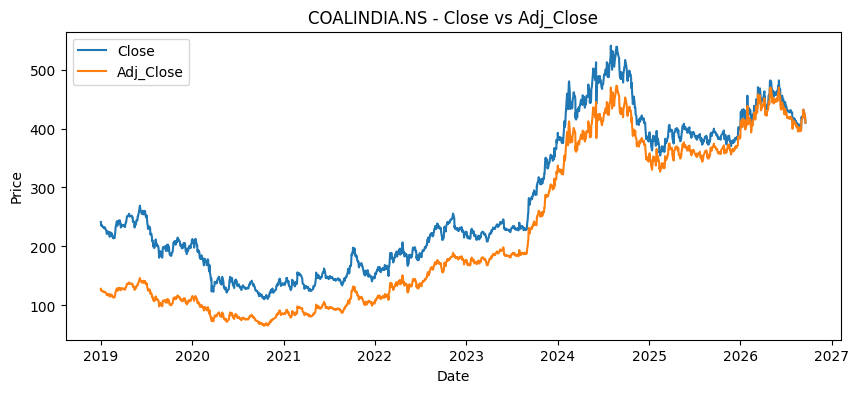

In [10]:
# pick the stock with the most jumps and plot it
plot_ticker = big_jumps["Ticker"].value_counts().index[0]
one_stock = df[df["Ticker"] == plot_ticker]

plt.figure(figsize=(10, 4))
plt.plot(one_stock["Date"], one_stock["Close"], label="Close")
plt.plot(one_stock["Date"], one_stock["Adj_Close"], label="Adj_Close")
plt.title(plot_ticker + " - Close vs Adj_Close")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.show()

## 9. Extra: splits / bonus issues via Volume vs Adj_Volume

In [11]:
# Close already seems to have splits fixed, so check volume instead
# Adj_Volume / Volume changes on the day of a split

# leave out zero volume rows, dividing by 0 gives nan
vol_check = df[df["Volume"] > 0][["Ticker", "Date", "Volume", "Adj_Volume"]].copy()
vol_check["vol_ratio"] = vol_check["Adj_Volume"] / vol_check["Volume"]
vol_check["prev_vol_ratio"] = vol_check.groupby("Ticker")["vol_ratio"].shift(1)

# ratio is different from yesterday = split or bonus
changed = vol_check["vol_ratio"] != vol_check["prev_vol_ratio"]

# first day of each stock has nothing to compare to, so skip it
has_prev = vol_check["prev_vol_ratio"].notna()

splits = vol_check[changed & has_prev]

print("possible split / bonus days:", len(splits))
print()
print(splits[["Ticker", "Date", "prev_vol_ratio", "vol_ratio"]].to_string(index=False))

possible split / bonus days: 4

       Ticker       Date  prev_vol_ratio  vol_ratio
  ASHOKLEY.NS 2025-07-16             2.0        1.0
   COFORGE.NS 2025-06-04             5.0        1.0
   HCLTECH.NS 2019-12-05             2.0        1.0
PIDILITIND.NS 2025-09-23             2.0        1.0


## 10. Extra: zero-volume rows

In [12]:
# zero volume means nothing was traded that day
zero_vol = df[df["Volume"] == 0]
print("rows with Volume == 0:", len(zero_vol))

print()
print("zero-volume stocks per date:")
print(zero_vol.groupby("Date")["Ticker"].nunique())

# if open, high, low and close are all the same, the price didn't move at all
same_open = zero_vol["Open"] == zero_vol["Close"]
same_high = zero_vol["High"] == zero_vol["Close"]
same_low = zero_vol["Low"] == zero_vol["Close"]
flat = same_open & same_high & same_low

print()
print("zero-volume rows where open = high = low = close:", flat.sum(), "out of", len(zero_vol))

rows with Volume == 0: 151

zero-volume stocks per date:
Date
2025-03-18    30
2025-09-08     1
2026-05-01    30
2026-05-28    30
2026-06-26    30
2026-09-14    30
Name: Ticker, dtype: int64

zero-volume rows where open = high = low = close: 151 out of 151


## 11. Stocks per sector

In [13]:
# one row per stock
stock_sectors = df[["Ticker", "Sector"]].drop_duplicates()

# a stock showing up twice here would mean it has two sectors
print("tickers with more than one sector:", stock_sectors["Ticker"].duplicated().sum(), "(expected 0)")

print()
print("stocks per sector:")
print(stock_sectors["Sector"].value_counts())

tickers with more than one sector: 0 (expected 0)

stocks per sector:
Sector
Healthcare                4
Banking                   4
Information Technology    4
Automobile                3
FMCG                      3
Capital Goods             2
Cement                    2
Consumer                  1
Auto Components           1
Mining                    1
Metals                    1
Engineering               1
Oil & Gas                 1
Chemicals                 1
Consumer Durables         1
Name: count, dtype: int64


## 12. Save the validated panel

In [14]:
# save as a new csv, the raw file stays the same
df.to_csv(OUT_PATH, index=False)
print("saved to:", OUT_PATH)

# load it back to check it saved properly
check = load_data(OUT_PATH)
print("shape after loading back:", check.shape)
print("same shape as before:", check.shape == df.shape)

saved to: ../data/processed/panel.csv
shape after loading back: (57300, 17)
same shape as before: True
